In [1]:
# 1-D4

In [2]:
# 2-D4
# Check the image-classification dataset tools
# and prepare the MNIST dataset.

import torch
from torchvision import datasets, transforms


# Convert each MNIST image into a PyTorch tensor.
transform = transforms.ToTensor()


# Download/load the MNIST training dataset.
train_dataset = datasets.MNIST(
    root="../../datasets",
    train=True,
    download=True,
    transform=transform
)


# Download/load the MNIST test dataset.
test_dataset = datasets.MNIST(
    root="../../datasets",
    train=False,
    download=True,
    transform=transform
)


print("Training samples:", len(train_dataset))
print("Test samples:", len(test_dataset))


# Inspect one sample.
image, label = train_dataset[0]

print("Image shape:", image.shape)
print("Label:", label)
print("Image data type:", image.dtype)

Training samples: 60000
Test samples: 10000
Image shape: torch.Size([1, 28, 28])
Label: 5
Image data type: torch.float32


In [3]:
# 3-D4
# Split the MNIST training dataset into
# training and validation subsets.

from torch.utils.data import random_split


# Define the number of samples for each subset.
train_size = 54000
validation_size = 6000


# Split the original training dataset.
train_subset, validation_subset = random_split(
    train_dataset,
    [train_size, validation_size],
    generator=torch.Generator().manual_seed(42)
)


print("Training subset:", len(train_subset))
print("Validation subset:", len(validation_subset))


# Inspect one sample from each subset.
train_image, train_label = train_subset[0]
validation_image, validation_label = validation_subset[0]


print("\nTraining sample:")
print("Image shape:", train_image.shape)
print("Label:", train_label)


print("\nValidation sample:")
print("Image shape:", validation_image.shape)
print("Label:", validation_label)

Training subset: 54000
Validation subset: 6000

Training sample:
Image shape: torch.Size([1, 28, 28])
Label: 6

Validation sample:
Image shape: torch.Size([1, 28, 28])
Label: 1


In [4]:
# 4-D4
# Create DataLoaders to provide training and validation
# data to the CNN in batches.

from torch.utils.data import DataLoader


# Define the number of images processed in one batch.
batch_size = 64


# Create the training DataLoader.
train_loader = DataLoader(
    train_subset,
    batch_size=batch_size,
    shuffle=True
)


# Create the validation DataLoader.
validation_loader = DataLoader(
    validation_subset,
    batch_size=batch_size,
    shuffle=False
)


# Get one batch from the training DataLoader.
train_images, train_labels = next(iter(train_loader))


# Get one batch from the validation DataLoader.
validation_images, validation_labels = next(iter(validation_loader))


print("Training batch image shape:", train_images.shape)
print("Training batch label shape:", train_labels.shape)

print("Validation batch image shape:", validation_images.shape)
print("Validation batch label shape:", validation_labels.shape)

Training batch image shape: torch.Size([64, 1, 28, 28])
Training batch label shape: torch.Size([64])
Validation batch image shape: torch.Size([64, 1, 28, 28])
Validation batch label shape: torch.Size([64])


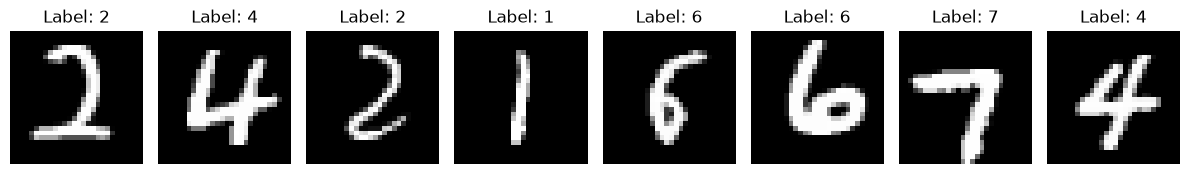

In [5]:
# 5-D4
# Visualize several images from one training batch
# together with their corresponding labels.

import matplotlib.pyplot as plt


# Select the first eight images from the batch.
images_to_show = train_images[:8]
labels_to_show = train_labels[:8]


# Create a row of eight image plots.
plt.figure(figsize=(12, 2))


for i in range(8):

    plt.subplot(1, 8, i + 1)

    # Remove the channel dimension for visualization.
    plt.imshow(
        images_to_show[i].squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Label: {labels_to_show[i].item()}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [6]:
# 6-D4
# Define the CNN classifier for MNIST digit classification.

import torch.nn as nn


class MNISTClassifier(nn.Module):

    def __init__(self):
        super().__init__()

        # First convolution:
        # 1 input channel (grayscale) -> 8 feature maps.
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=8,
            kernel_size=3,
            padding=1
        )

        # Second convolution:
        # 8 feature maps -> 16 feature maps.
        self.conv2 = nn.Conv2d(
            in_channels=8,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Reduce the spatial dimensions by a factor of 2.
        self.pool = nn.MaxPool2d(
            kernel_size=2,
            stride=2
        )

        # Fully connected classification layer.
        # After two pooling operations:
        # 16 feature maps × 7 × 7 = 784 values.
        self.fc = nn.Linear(
            16 * 7 * 7,
            10
        )

    def forward(self, x):

        # First convolution and activation.
        x = self.conv1(x)
        x = torch.relu(x)

        # First spatial reduction.
        x = self.pool(x)

        # Second convolution and activation.
        x = self.conv2(x)
        x = torch.relu(x)

        # Second spatial reduction.
        x = self.pool(x)

        # Flatten each image into a one-dimensional vector.
        x = x.view(
            x.size(0),
            -1
        )

        # Produce one output value for each digit class.
        x = self.fc(x)

        return x


model = MNISTClassifier()

print(model)

MNISTClassifier(
  (conv1): Conv2d(1, 8, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(8, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc): Linear(in_features=784, out_features=10, bias=True)
)


In [7]:
# 7-D4
# Define the loss function and optimizer
# used to train the CNN.

# Cross-entropy loss measures the difference between
# the model's class scores and the correct class labels.
loss_function = nn.CrossEntropyLoss()


# Adam updates the CNN parameters using the gradients
# calculated during backpropagation.
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


print("Loss function:", loss_function)
print("Optimizer:", optimizer)

Loss function: CrossEntropyLoss()
Optimizer: Adam (
Parameter Group 0
    amsgrad: False
    betas: (0.9, 0.999)
    capturable: False
    decoupled_weight_decay: False
    differentiable: False
    eps: 1e-08
    foreach: None
    fused: None
    lr: 0.001
    maximize: False
    weight_decay: 0
)


In [8]:
# 8-D4
# Run one real training batch through the CNN
# and calculate the corresponding loss.

# Take one batch of real MNIST images.
images, labels = next(iter(train_loader))


# Pass the images through the CNN.
outputs = model(images)


# Compare the model outputs with the correct labels.
loss = loss_function(
    outputs,
    labels
)


print("Input batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Model output shape:", outputs.shape)
print("Loss:", loss.item())

Input batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])
Model output shape: torch.Size([64, 10])
Loss: 2.285792589187622


In [9]:
# 9-D4
# Inspect the CNN's initial prediction for one real image.

# Select the first image and its corresponding label.
single_image = images[0]
true_label = labels[0]


# Add the batch dimension back because the CNN expects a batch.
single_image_batch = single_image.unsqueeze(0)


# Run the image through the model.
single_output = model(single_image_batch)


# Find the class with the highest output score.
predicted_class = torch.argmax(
    single_output,
    dim=1
)


print("True label:", true_label.item())
print("Model output:", single_output)
print("Predicted class:", predicted_class.item())

True label: 5
Model output: tensor([[-0.0300, -0.1392, -0.0156,  0.0922,  0.0001, -0.1375, -0.1399,  0.0603,
          0.0542, -0.0469]], grad_fn=<AddmmBackward0>)
Predicted class: 3


In [10]:
# 10-D4
# Perform one training step on a single batch.

# Start with cleared gradients.
optimizer.zero_grad()


# Forward pass:
# send the training images through the CNN.
outputs = model(images)


# Calculate how wrong the predictions are.
loss = loss_function(
    outputs,
    labels
)


# Backward pass:
# calculate gradients for the model parameters.
loss.backward()


# Update the model parameters using the gradients.
optimizer.step()


print("Training loss:", loss.item())

Training loss: 2.285792589187622


In [11]:
# 11-D4
# Measure the model output after the weight update.

# Run the same batch through the updated model.
updated_outputs = model(images)


# Calculate the new loss using the updated weights.
updated_loss = loss_function(
    updated_outputs,
    labels
)


print("Loss after weight update:", updated_loss.item())


# Get the predicted class for each image.
updated_predictions = torch.argmax(
    updated_outputs,
    dim=1
)


# Calculate the number of correct predictions.
correct_predictions = (
    updated_predictions == labels
).sum().item()


print("Correct predictions:", correct_predictions)
print("Batch size:", labels.size(0))

Loss after weight update: 2.2575950622558594
Correct predictions: 10
Batch size: 64


In [12]:
# 12-D4
# Train the CNN for one epoch over the training dataset.

model.train()

running_loss = 0.0
correct = 0
total = 0


for batch_images, batch_labels in train_loader:

    # Clear gradients from the previous batch.
    optimizer.zero_grad()

    # Forward pass.
    outputs = model(batch_images)

    # Calculate the loss.
    loss = loss_function(
        outputs,
        batch_labels
    )

    # Backward pass.
    loss.backward()

    # Update model parameters.
    optimizer.step()

    # Accumulate the loss.
    running_loss += loss.item()

    # Determine the predicted class for each image.
    predictions = torch.argmax(
        outputs,
        dim=1
    )

    # Count correct predictions.
    correct += (
        predictions == batch_labels
    ).sum().item()

    total += batch_labels.size(0)


average_loss = running_loss / len(train_loader)
accuracy = 100 * correct / total


print("Training loss:", average_loss)
print("Training accuracy:", accuracy)

Training loss: 0.34236219984819116
Training accuracy: 90.53148148148148


In [13]:
# 13-D4
# Evaluate the trained CNN on the validation dataset.

model.eval()

validation_loss = 0.0
validation_correct = 0
validation_total = 0


with torch.no_grad():

    for batch_images, batch_labels in validation_loader:

        # Forward pass through the trained model.
        outputs = model(batch_images)

        # Calculate validation loss.
        loss = loss_function(
            outputs,
            batch_labels
        )

        validation_loss += loss.item()

        # Determine the predicted class.
        predictions = torch.argmax(
            outputs,
            dim=1
        )

        # Count correct predictions.
        validation_correct += (
            predictions == batch_labels
        ).sum().item()

        validation_total += batch_labels.size(0)


average_validation_loss = (
    validation_loss / len(validation_loader)
)

validation_accuracy = (
    100 * validation_correct / validation_total
)


print("Validation loss:", average_validation_loss)
print("Validation accuracy:", validation_accuracy)

Validation loss: 0.14644341654282936
Validation accuracy: 95.7


In [14]:
# 14-D4
# Evaluate the trained CNN on the separate MNIST test dataset.

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)


model.eval()

test_correct = 0
test_total = 0


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_correct += (
            predictions == batch_labels
        ).sum().item()

        test_total += batch_labels.size(0)


test_accuracy = (
    100 * test_correct / test_total
)


print("Test correct predictions:", test_correct)
print("Test samples:", test_total)
print("Test accuracy:", test_accuracy)

Test correct predictions: 9643
Test samples: 10000
Test accuracy: 96.43


In [15]:
# 15-D5
# Identify incorrectly classified images from the test dataset.

model.eval()

incorrect_images = []
incorrect_labels = []
incorrect_predictions = []


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        incorrect_mask = predictions != batch_labels

        incorrect_images.extend(
            batch_images[incorrect_mask]
        )

        incorrect_labels.extend(
            batch_labels[incorrect_mask]
        )

        incorrect_predictions.extend(
            predictions[incorrect_mask]
        )


print("Incorrect predictions:", len(incorrect_images))
print("Total test samples:", test_total)
print(
    "Error rate:",
    100 * len(incorrect_images) / test_total
)

Incorrect predictions: 357
Total test samples: 10000
Error rate: 3.57


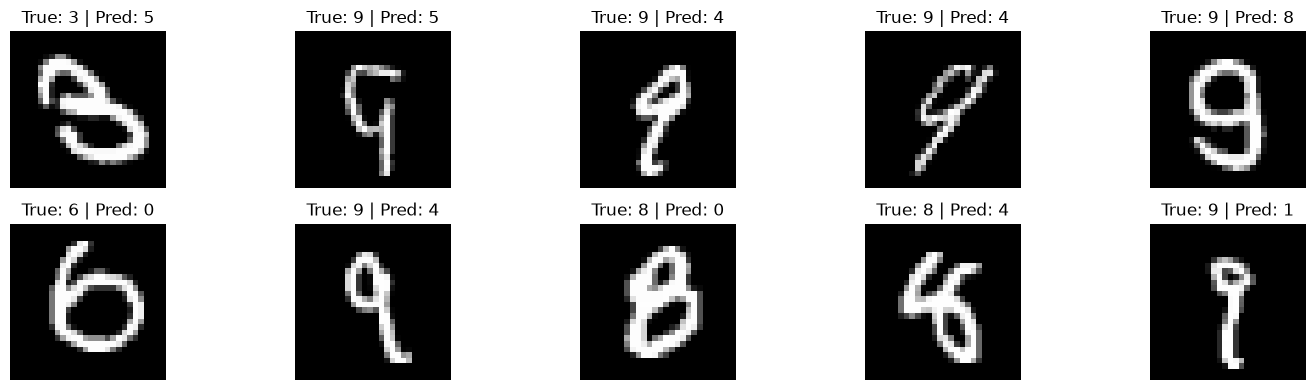

In [16]:
# 16-D5
# Visualize a sample of incorrectly classified test images.

import matplotlib.pyplot as plt


num_examples = min(10, len(incorrect_images))

plt.figure(figsize=(15, 4))


for i in range(num_examples):

    plt.subplot(2, 5, i + 1)

    image = incorrect_images[i].squeeze()

    true_label = incorrect_labels[i]
    predicted_label = incorrect_predictions[i]

    plt.imshow(
        image,
        cmap="gray"
    )

    plt.title(
        f"True: {true_label} | Pred: {predicted_label}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [18]:
# 17-D5
# Build a confusion matrix for the test-set predictions.

all_true_labels = []
all_predictions = []


model.eval()

with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        all_true_labels.extend(
            batch_labels.tolist()
        )

        all_predictions.extend(
            predictions.tolist()
        )


# Create an empty 10 × 10 confusion matrix.
# Rows represent true classes.
# Columns represent predicted classes.
conf_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)


# Count every true-label / predicted-label pair.
for true_label, predicted_label in zip(
    all_true_labels,
    all_predictions
):
    conf_matrix[
        true_label,
        predicted_label
    ] += 1


print("Confusion matrix:")
print(conf_matrix)

Confusion matrix:
tensor([[ 972,    0,    2,    0,    0,    2,    2,    1,    1,    0],
        [   0, 1118,   11,    0,    2,    0,    2,    0,    2,    0],
        [   5,    0, 1010,    5,    3,    0,    0,    6,    3,    0],
        [   1,    0,   10,  979,    1,    8,    0,    6,    4,    1],
        [   1,    0,    1,    1,  967,    0,    5,    3,    2,    2],
        [   6,    1,    1,   12,    0,  861,    5,    1,    4,    1],
        [   9,    1,    1,    1,    5,    2,  937,    0,    2,    0],
        [   2,    4,   27,    5,    1,    0,    0,  982,    0,    7],
        [  12,    0,   19,    9,   13,    4,    7,    8,  896,    6],
        [  11,    6,    4,    8,   36,    8,    0,   10,    5,  921]])


In [19]:
# 18-D5
# Find the most common incorrect class predictions.

confusion_pairs = []


for true_label in range(10):

    for predicted_label in range(10):

        # Ignore the diagonal because those are correct predictions.
        if true_label != predicted_label:

            count = conf_matrix[
                true_label,
                predicted_label
            ].item()

            confusion_pairs.append(
                (
                    count,
                    true_label,
                    predicted_label
                )
            )


# Sort from the most frequent error to the least frequent error.
confusion_pairs.sort(
    reverse=True
)


print("Most common classification errors:")

for count, true_label, predicted_label in confusion_pairs[:10]:

    print(
        f"True {true_label} -> "
        f"Predicted {predicted_label}: "
        f"{count}"
    )

Most common classification errors:
True 9 -> Predicted 4: 36
True 7 -> Predicted 2: 27
True 8 -> Predicted 2: 19
True 8 -> Predicted 4: 13
True 8 -> Predicted 0: 12
True 5 -> Predicted 3: 12
True 9 -> Predicted 0: 11
True 1 -> Predicted 2: 11
True 9 -> Predicted 7: 10
True 3 -> Predicted 2: 10


In [20]:
# 19-D5
# Calculate the classification accuracy for each true digit class.

print("Per-class test accuracy:")


for true_label in range(10):

    total_for_class = conf_matrix[
        true_label
    ].sum().item()

    correct_for_class = conf_matrix[
        true_label,
        true_label
    ].item()

    class_accuracy = (
        100 * correct_for_class / total_for_class
    )

    print(
        f"Digit {true_label}: "
        f"{class_accuracy:.2f}% "
        f"({correct_for_class}/{total_for_class})"
    )

Per-class test accuracy:
Digit 0: 99.18% (972/980)
Digit 1: 98.50% (1118/1135)
Digit 2: 97.87% (1010/1032)
Digit 3: 96.93% (979/1010)
Digit 4: 98.47% (967/982)
Digit 5: 96.52% (861/892)
Digit 6: 97.81% (937/958)
Digit 7: 95.53% (982/1028)
Digit 8: 91.99% (896/974)
Digit 9: 91.28% (921/1009)


In [21]:
# 20-D5
# Preserve the current model and optimizer state as the Day 5 baseline.

import copy


baseline_model_state = copy.deepcopy(
    model.state_dict()
)

baseline_optimizer_state = copy.deepcopy(
    optimizer.state_dict()
)


baseline_test_accuracy = test_accuracy


print(
    "Baseline test accuracy:",
    baseline_test_accuracy
)

print(
    "Baseline model state preserved:",
    len(baseline_model_state),
    "parameter groups"
)

Baseline test accuracy: 96.43
Baseline model state preserved: 6 parameter groups


In [22]:
# 21-D5
# Train the CNN for multiple epochs without data augmentation.
# This establishes the no-augmentation baseline.

num_epochs = 5

train_losses = []
train_accuracies = []

validation_losses = []
validation_accuracies = []


for epoch in range(num_epochs):

    # -------------------------
    # Training
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for batch_images, batch_labels in train_loader:

        optimizer.zero_grad()

        outputs = model(batch_images)

        loss = loss_function(
            outputs,
            batch_labels
        )

        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)


    epoch_train_loss = (
        running_loss / len(train_loader)
    )

    epoch_train_accuracy = (
        100 * correct / total
    )


    # -------------------------
    # Validation
    # -------------------------

    model.eval()

    validation_loss = 0.0
    validation_correct = 0
    validation_total = 0


    with torch.no_grad():

        for batch_images, batch_labels in validation_loader:

            outputs = model(batch_images)

            loss = loss_function(
                outputs,
                batch_labels
            )

            validation_loss += loss.item()

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            validation_correct += (
                predictions == batch_labels
            ).sum().item()

            validation_total += batch_labels.size(0)


    epoch_validation_loss = (
        validation_loss / len(validation_loader)
    )

    epoch_validation_accuracy = (
        100 * validation_correct / validation_total
    )


    # -------------------------
    # Store results
    # -------------------------

    train_losses.append(
        epoch_train_loss
    )

    train_accuracies.append(
        epoch_train_accuracy
    )

    validation_losses.append(
        epoch_validation_loss
    )

    validation_accuracies.append(
        epoch_validation_accuracy
    )


    print(
        f"Epoch {epoch + 1}/{num_epochs}"
    )

    print(
        f"Training loss: {epoch_train_loss:.4f}"
    )

    print(
        f"Training accuracy: "
        f"{epoch_train_accuracy:.2f}%"
    )

    print(
        f"Validation loss: "
        f"{epoch_validation_loss:.4f}"
    )

    print(
        f"Validation accuracy: "
        f"{epoch_validation_accuracy:.2f}%"
    )

    print()

Epoch 1/5
Training loss: 0.1027
Training accuracy: 96.96%
Validation loss: 0.1005
Validation accuracy: 97.15%

Epoch 2/5
Training loss: 0.0763
Training accuracy: 97.69%
Validation loss: 0.0781
Validation accuracy: 97.87%

Epoch 3/5
Training loss: 0.0620
Training accuracy: 98.12%
Validation loss: 0.0700
Validation accuracy: 97.97%

Epoch 4/5
Training loss: 0.0529
Training accuracy: 98.39%
Validation loss: 0.0670
Validation accuracy: 97.92%

Epoch 5/5
Training loss: 0.0471
Training accuracy: 98.59%
Validation loss: 0.0638
Validation accuracy: 98.07%



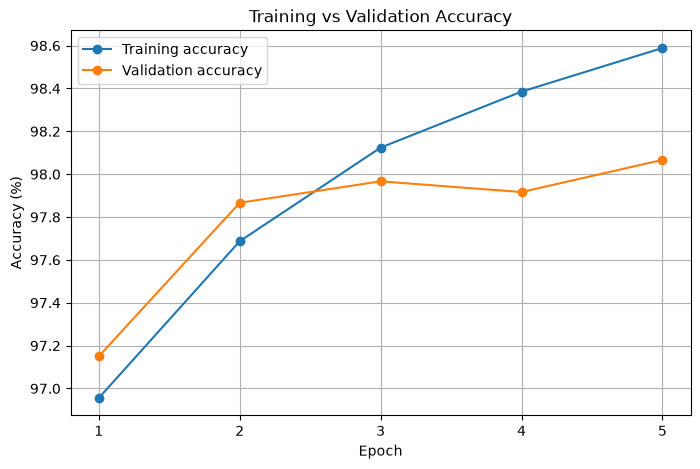

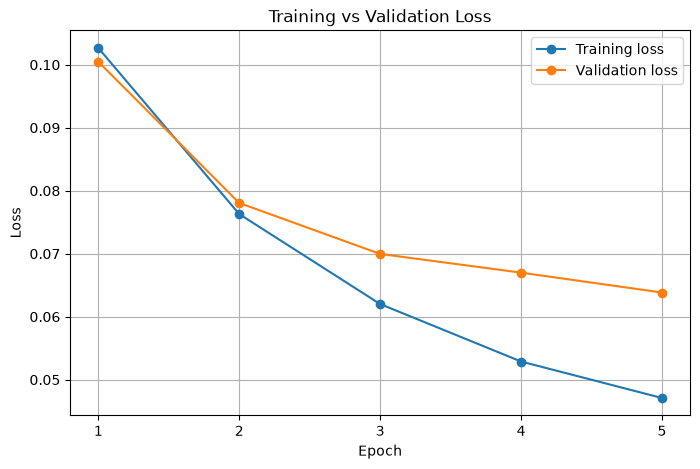

In [24]:
# 22-D5
# Visualize training and validation performance across epochs.

import matplotlib.pyplot as plt


epochs = range(1, num_epochs + 1)


plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_accuracies,
    marker="o",
    label="Training accuracy"
)

plt.plot(
    epochs,
    validation_accuracies,
    marker="o",
    label="Validation accuracy"
)

plt.xlabel("Epoch")
plt.ylabel("Accuracy (%)")
plt.title("Training vs Validation Accuracy")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.show()

plt.figure(figsize=(8, 5))

plt.plot(
    epochs,
    train_losses,
    marker="o",
    label="Training loss"
)

plt.plot(
    epochs,
    validation_losses,
    marker="o",
    label="Validation loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs Validation Loss")
plt.xticks(list(epochs))
plt.legend()
plt.grid(True)

plt.show()

In [25]:
# 23-D5
# Evaluate the multi-epoch no-augmentation model on the test dataset.

model.eval()

test_correct = 0
test_total = 0


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        test_correct += (
            predictions == batch_labels
        ).sum().item()

        test_total += batch_labels.size(0)


multi_epoch_test_accuracy = (
    100 * test_correct / test_total
)


print(
    "Test correct predictions:",
    test_correct
)

print(
    "Test samples:",
    test_total
)

print(
    "Test accuracy after 5 additional epochs:",
    multi_epoch_test_accuracy
)

Test correct predictions: 9858
Test samples: 10000
Test accuracy after 5 additional epochs: 98.58


In [26]:
# 24-D5
# Create a basic data-augmentation pipeline for the training images.

from torchvision import transforms


augmentation_transform = transforms.Compose([
    transforms.RandomRotation(10),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.10, 0.10),
        scale=(0.90, 1.10)
    ),
    transforms.ToTensor()
])


print("Augmentation pipeline:")
print(augmentation_transform)

Augmentation pipeline:
Compose(
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    RandomAffine(degrees=[0.0, 0.0], translate=(0.1, 0.1), scale=(0.9, 1.1))
    ToTensor()
)


In [33]:
# 25-D5
# Create an augmented version of the existing training subset.
# The validation subset remains unchanged.

from torchvision import datasets
from torch.utils.data import Subset, DataLoader


augmented_full_dataset = datasets.MNIST(
    root="../../datasets/MNIST",
    train=True,
    download=False,
    transform=augmentation_transform
)


augmented_train_dataset = Subset(
    augmented_full_dataset,
    train_subset.indices
)


augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=64,
    shuffle=True
)


print(
    "Augmented training samples:",
    len(augmented_train_dataset)
)

print(
    "Validation samples:",
    len(validation_subset)
)

print(
    "Augmented training batch shape:",
    next(iter(augmented_train_loader))[0].shape
)

RuntimeError: Dataset not found. You can use download=True to download it

In [31]:
# 26-D5
# Inspect the existing MNIST dataset location.

print(
    "Dataset type:",
    type(train_dataset)
)

print(
    "Dataset root:",
    train_dataset.root
)

print(
    "Dataset training split:",
    train_dataset.train
)

print(
    "Number of training indices:",
    len(train_subset.indices)
)

Dataset type: <class 'torchvision.datasets.mnist.MNIST'>
Dataset root: ../../datasets
Dataset training split: True
Number of training indices: 54000


In [34]:
# 27-D5
# Create an augmented version of the existing training subset.
# The validation and test datasets remain unchanged.

from torchvision import datasets
from torch.utils.data import Subset, DataLoader


augmented_full_dataset = datasets.MNIST(
    root=train_dataset.root,
    train=True,
    download=False,
    transform=augmentation_transform
)


augmented_train_dataset = Subset(
    augmented_full_dataset,
    train_subset.indices
)


augmented_train_loader = DataLoader(
    augmented_train_dataset,
    batch_size=64,
    shuffle=True
)


print(
    "Augmented training samples:",
    len(augmented_train_dataset)
)

print(
    "Validation samples:",
    len(validation_subset)
)

print(
    "Augmented training batch shape:",
    next(iter(augmented_train_loader))[0].shape
)

Augmented training samples: 54000
Validation samples: 6000
Augmented training batch shape: torch.Size([64, 1, 28, 28])


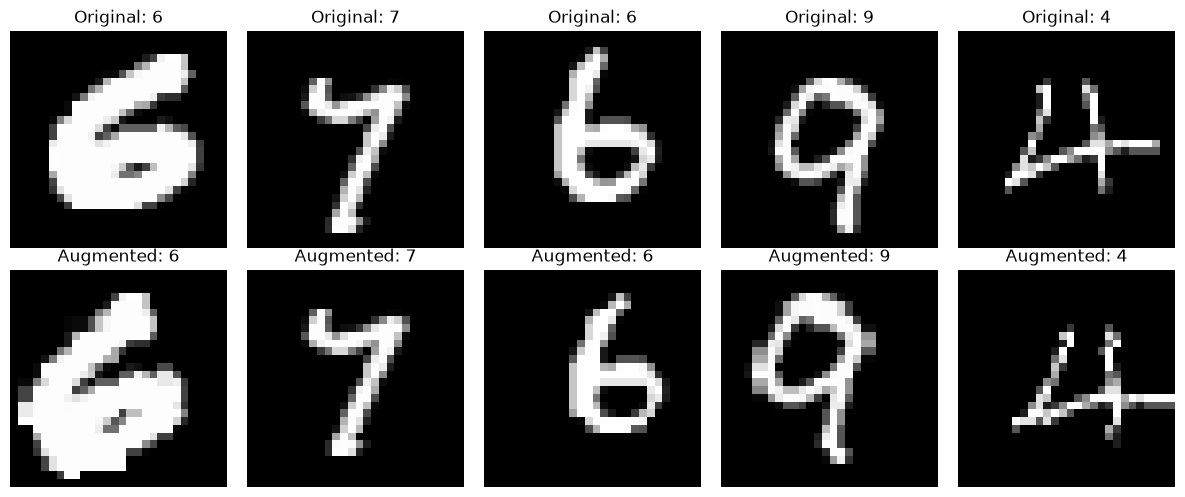

In [35]:
# 28-D5
# Compare original training images with their augmented versions.

import matplotlib.pyplot as plt


num_examples = 5

plt.figure(figsize=(12, 5))


for i in range(num_examples):

    # Get the same underlying sample from both datasets.
    original_image, original_label = train_subset[i]
    augmented_image, augmented_label = augmented_train_dataset[i]

    # Original image.
    plt.subplot(2, num_examples, i + 1)

    plt.imshow(
        original_image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Original: {original_label}"
    )

    plt.axis("off")


    # Augmented image.
    plt.subplot(
        2,
        num_examples,
        num_examples + i + 1
    )

    plt.imshow(
        augmented_image.squeeze(),
        cmap="gray"
    )

    plt.title(
        f"Augmented: {augmented_label}"
    )

    plt.axis("off")


plt.tight_layout()
plt.show()

In [36]:
# 29-D5
# Restore the preserved Day 5 baseline before the augmentation experiment.

model.load_state_dict(
    baseline_model_state
)

optimizer.load_state_dict(
    baseline_optimizer_state
)


print(
    "Model restored to baseline state."
)

print(
    "Baseline test accuracy:",
    baseline_test_accuracy
)

Model restored to baseline state.
Baseline test accuracy: 96.43


In [37]:
# 30-D5
# Train the CNN using the augmented training dataset.

num_augmented_epochs = 5

augmented_train_losses = []
augmented_train_accuracies = []

augmented_validation_losses = []
augmented_validation_accuracies = []


for epoch in range(num_augmented_epochs):

    # -------------------------
    # Training
    # -------------------------

    model.train()

    running_loss = 0.0
    correct = 0
    total = 0


    for batch_images, batch_labels in augmented_train_loader:

        optimizer.zero_grad()

        outputs = model(batch_images)

        loss = loss_function(
            outputs,
            batch_labels
        )

        loss.backward()

        optimizer.step()


        running_loss += loss.item()

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        correct += (
            predictions == batch_labels
        ).sum().item()

        total += batch_labels.size(0)


    epoch_train_loss = (
        running_loss / len(augmented_train_loader)
    )

    epoch_train_accuracy = (
        100 * correct / total
    )


    # -------------------------
    # Validation
    # -------------------------

    model.eval()

    validation_loss = 0.0
    validation_correct = 0
    validation_total = 0


    with torch.no_grad():

        for batch_images, batch_labels in validation_loader:

            outputs = model(batch_images)

            loss = loss_function(
                outputs,
                batch_labels
            )

            validation_loss += loss.item()

            predictions = torch.argmax(
                outputs,
                dim=1
            )

            validation_correct += (
                predictions == batch_labels
            ).sum().item()

            validation_total += batch_labels.size(0)


    epoch_validation_loss = (
        validation_loss / len(validation_loader)
    )

    epoch_validation_accuracy = (
        100 * validation_correct / validation_total
    )


    # -------------------------
    # Store results
    # -------------------------

    augmented_train_losses.append(
        epoch_train_loss
    )

    augmented_train_accuracies.append(
        epoch_train_accuracy
    )

    augmented_validation_losses.append(
        epoch_validation_loss
    )

    augmented_validation_accuracies.append(
        epoch_validation_accuracy
    )


    print(
        f"Augmented Epoch "
        f"{epoch + 1}/{num_augmented_epochs}"
    )

    print(
        f"Training loss: "
        f"{epoch_train_loss:.4f}"
    )

    print(
        f"Training accuracy: "
        f"{epoch_train_accuracy:.2f}%"
    )

    print(
        f"Validation loss: "
        f"{epoch_validation_loss:.4f}"
    )

    print(
        f"Validation accuracy: "
        f"{epoch_validation_accuracy:.2f}%"
    )

    print()

Augmented Epoch 1/5
Training loss: 0.3398
Training accuracy: 89.53%
Validation loss: 0.1204
Validation accuracy: 96.37%

Augmented Epoch 2/5
Training loss: 0.2167
Training accuracy: 93.45%
Validation loss: 0.1008
Validation accuracy: 97.05%

Augmented Epoch 3/5
Training loss: 0.1868
Training accuracy: 94.40%
Validation loss: 0.0880
Validation accuracy: 97.40%

Augmented Epoch 4/5
Training loss: 0.1649
Training accuracy: 95.00%
Validation loss: 0.0786
Validation accuracy: 97.65%

Augmented Epoch 5/5
Training loss: 0.1508
Training accuracy: 95.42%
Validation loss: 0.0668
Validation accuracy: 97.95%



In [38]:
# 31-D5
# Evaluate the augmented model on the unchanged test dataset.

model.eval()

augmented_test_correct = 0
augmented_test_total = 0


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )

        augmented_test_correct += (
            predictions == batch_labels
        ).sum().item()

        augmented_test_total += (
            batch_labels.size(0)
        )


augmented_test_accuracy = (
    100
    * augmented_test_correct
    / augmented_test_total
)


print(
    "Augmented model test correct predictions:",
    augmented_test_correct
)

print(
    "Test samples:",
    augmented_test_total
)

print(
    "Augmented model test accuracy:",
    augmented_test_accuracy
)

print(
    "No-augmentation baseline:",
    multi_epoch_test_accuracy
)

print(
    "Difference:",
    augmented_test_accuracy
    - multi_epoch_test_accuracy
)

Augmented model test correct predictions: 9844
Test samples: 10000
Augmented model test accuracy: 98.44
No-augmentation baseline: 98.58
Difference: -0.14000000000000057


In [39]:
# 32-D5
# Compare per-class accuracy before and after augmentation.

augmented_conf_matrix = torch.zeros(
    10,
    10,
    dtype=torch.int64
)


model.eval()


with torch.no_grad():

    for batch_images, batch_labels in test_loader:

        outputs = model(batch_images)

        predictions = torch.argmax(
            outputs,
            dim=1
        )


        for true_label, predicted_label in zip(
            batch_labels.tolist(),
            predictions.tolist()
        ):

            augmented_conf_matrix[
                true_label,
                predicted_label
            ] += 1


print("Per-class accuracy comparison:")
print()


for true_label in range(10):

    baseline_total = conf_matrix[
        true_label
    ].sum().item()

    baseline_correct = conf_matrix[
        true_label,
        true_label
    ].item()


    augmented_total = augmented_conf_matrix[
        true_label
    ].sum().item()

    augmented_correct = augmented_conf_matrix[
        true_label,
        true_label
    ].item()


    baseline_accuracy = (
        100 * baseline_correct / baseline_total
    )

    augmented_accuracy = (
        100 * augmented_correct / augmented_total
    )


    difference = (
        augmented_accuracy
        - baseline_accuracy
    )


    print(
        f"Digit {true_label}: "
        f"Baseline = {baseline_accuracy:.2f}% | "
        f"Augmented = {augmented_accuracy:.2f}% | "
        f"Difference = {difference:+.2f}%"
    )

Per-class accuracy comparison:

Digit 0: Baseline = 99.18% | Augmented = 99.29% | Difference = +0.10%
Digit 1: Baseline = 98.50% | Augmented = 99.03% | Difference = +0.53%
Digit 2: Baseline = 97.87% | Augmented = 99.13% | Difference = +1.26%
Digit 3: Baseline = 96.93% | Augmented = 98.71% | Difference = +1.78%
Digit 4: Baseline = 98.47% | Augmented = 97.15% | Difference = -1.32%
Digit 5: Baseline = 96.52% | Augmented = 99.33% | Difference = +2.80%
Digit 6: Baseline = 97.81% | Augmented = 98.96% | Difference = +1.15%
Digit 7: Baseline = 95.53% | Augmented = 97.96% | Difference = +2.43%
Digit 8: Baseline = 91.99% | Augmented = 97.84% | Difference = +5.85%
Digit 9: Baseline = 91.28% | Augmented = 97.03% | Difference = +5.75%


In [40]:
# 33-D5
# Verify the augmented test accuracy directly from the confusion matrix.

print(
    "Augmented confusion-matrix total:",
    augmented_conf_matrix.sum().item()
)

print(
    "Augmented correct predictions:",
    torch.diag(augmented_conf_matrix).sum().item()
)

print(
    "Augmented accuracy from confusion matrix:",
    100
    * torch.diag(augmented_conf_matrix).sum().item()
    / augmented_conf_matrix.sum().item()
)

print(
    "Previously reported augmented accuracy:",
    augmented_test_accuracy
)

print(
    "Previously reported correct predictions:",
    augmented_test_correct
)

Augmented confusion-matrix total: 10000
Augmented correct predictions: 9844
Augmented accuracy from confusion matrix: 98.44
Previously reported augmented accuracy: 98.44
Previously reported correct predictions: 9844


In [41]:
# 34-D5
# Record the baseline vs augmented experiment.

print("Data augmentation experiment")
print("--------------------------------")
print(f"Baseline test accuracy:   {multi_epoch_test_accuracy:.2f}%")
print(f"Augmented test accuracy:  {augmented_test_accuracy:.2f}%")
print(
    f"Overall difference:       "
    f"{augmented_test_accuracy - multi_epoch_test_accuracy:+.2f} percentage points"
)

print()
print("Key class-level changes:")
print("Digit 8: +5.85 percentage points")
print("Digit 9: +5.75 percentage points")
print("Digit 7: +2.43 percentage points")
print("Digit 5: +2.80 percentage points")
print("Digit 4: -1.32 percentage points")

Data augmentation experiment
--------------------------------
Baseline test accuracy:   98.58%
Augmented test accuracy:  98.44%
Overall difference:       -0.14 percentage points

Key class-level changes:
Digit 8: +5.85 percentage points
Digit 9: +5.75 percentage points
Digit 7: +2.43 percentage points
Digit 5: +2.80 percentage points
Digit 4: -1.32 percentage points


In [44]:
# 35-D5
# Final Day-5 experiment summary.

day5_results = {
    "baseline_test_accuracy": multi_epoch_test_accuracy,
    "augmented_test_accuracy": augmented_test_accuracy,
    "overall_difference": (
        augmented_test_accuracy - multi_epoch_test_accuracy
    ),
}

print("Day 5 final result:")
print(day5_results)

Day 5 final result:
{'baseline_test_accuracy': 98.58, 'augmented_test_accuracy': 98.44, 'overall_difference': -0.14000000000000057}
